# Problem Setup
Here we present the usage of pytorch's automatic differentiation algorithm.

We use the model trained in the previous section in order to obtain its derivatives through the automatic differentiation algorithm:

$$f(x)=sin(x)$$

$$\frac{d f(x)}{d x}=cos(x)$$

# Libraries

In [1]:
from Lib.MultiLayerNet import *

CUDA not available, running on CPU


# Tunning Parameters

In [2]:
N = 500

# Functions

In [3]:
def f(x):
    y=np.sin(x)
    return y 

def df(x):
    dy = np.cos(x)
    return dy

In [4]:
def mygrad(y, x):
    dydx = grad(y, x, torch.ones(x.size()[0], 1, device=dev),
                create_graph=True, retain_graph=True)[0]
    return dydx

# Load Model

In [5]:
# Set Neural Network
layers = [1,30,30,30,1]
model = MultiLayerNet(layers, init=True)
model.to(dev)
start_time = time.time()

model.load_state_dict(torch.load('./output/Case1/model.pt', map_location=torch.device(dev)))
model.eval()

Constructor: Init Network!


MultiLayerNet(
  (activation): Tanh()
  (linears): ModuleList(
    (0): Linear(in_features=1, out_features=30, bias=True)
    (1-2): 2 x Linear(in_features=30, out_features=30, bias=True)
    (3): Linear(in_features=30, out_features=1, bias=True)
  )
)

In [6]:
x_test = torch.linspace(0,2*np.pi,N).view(-1,1)
x_test.requires_grad_(True)

y_pred = model(x_test)
dy_pred = mygrad(y_pred, x_test)

x_test = x_test.detach().cpu().numpy()
y_real = f(x_test)
dy_real = df(x_test)

y_pred = y_pred.detach().cpu().numpy()
dy_pred = dy_pred.detach().cpu().numpy()

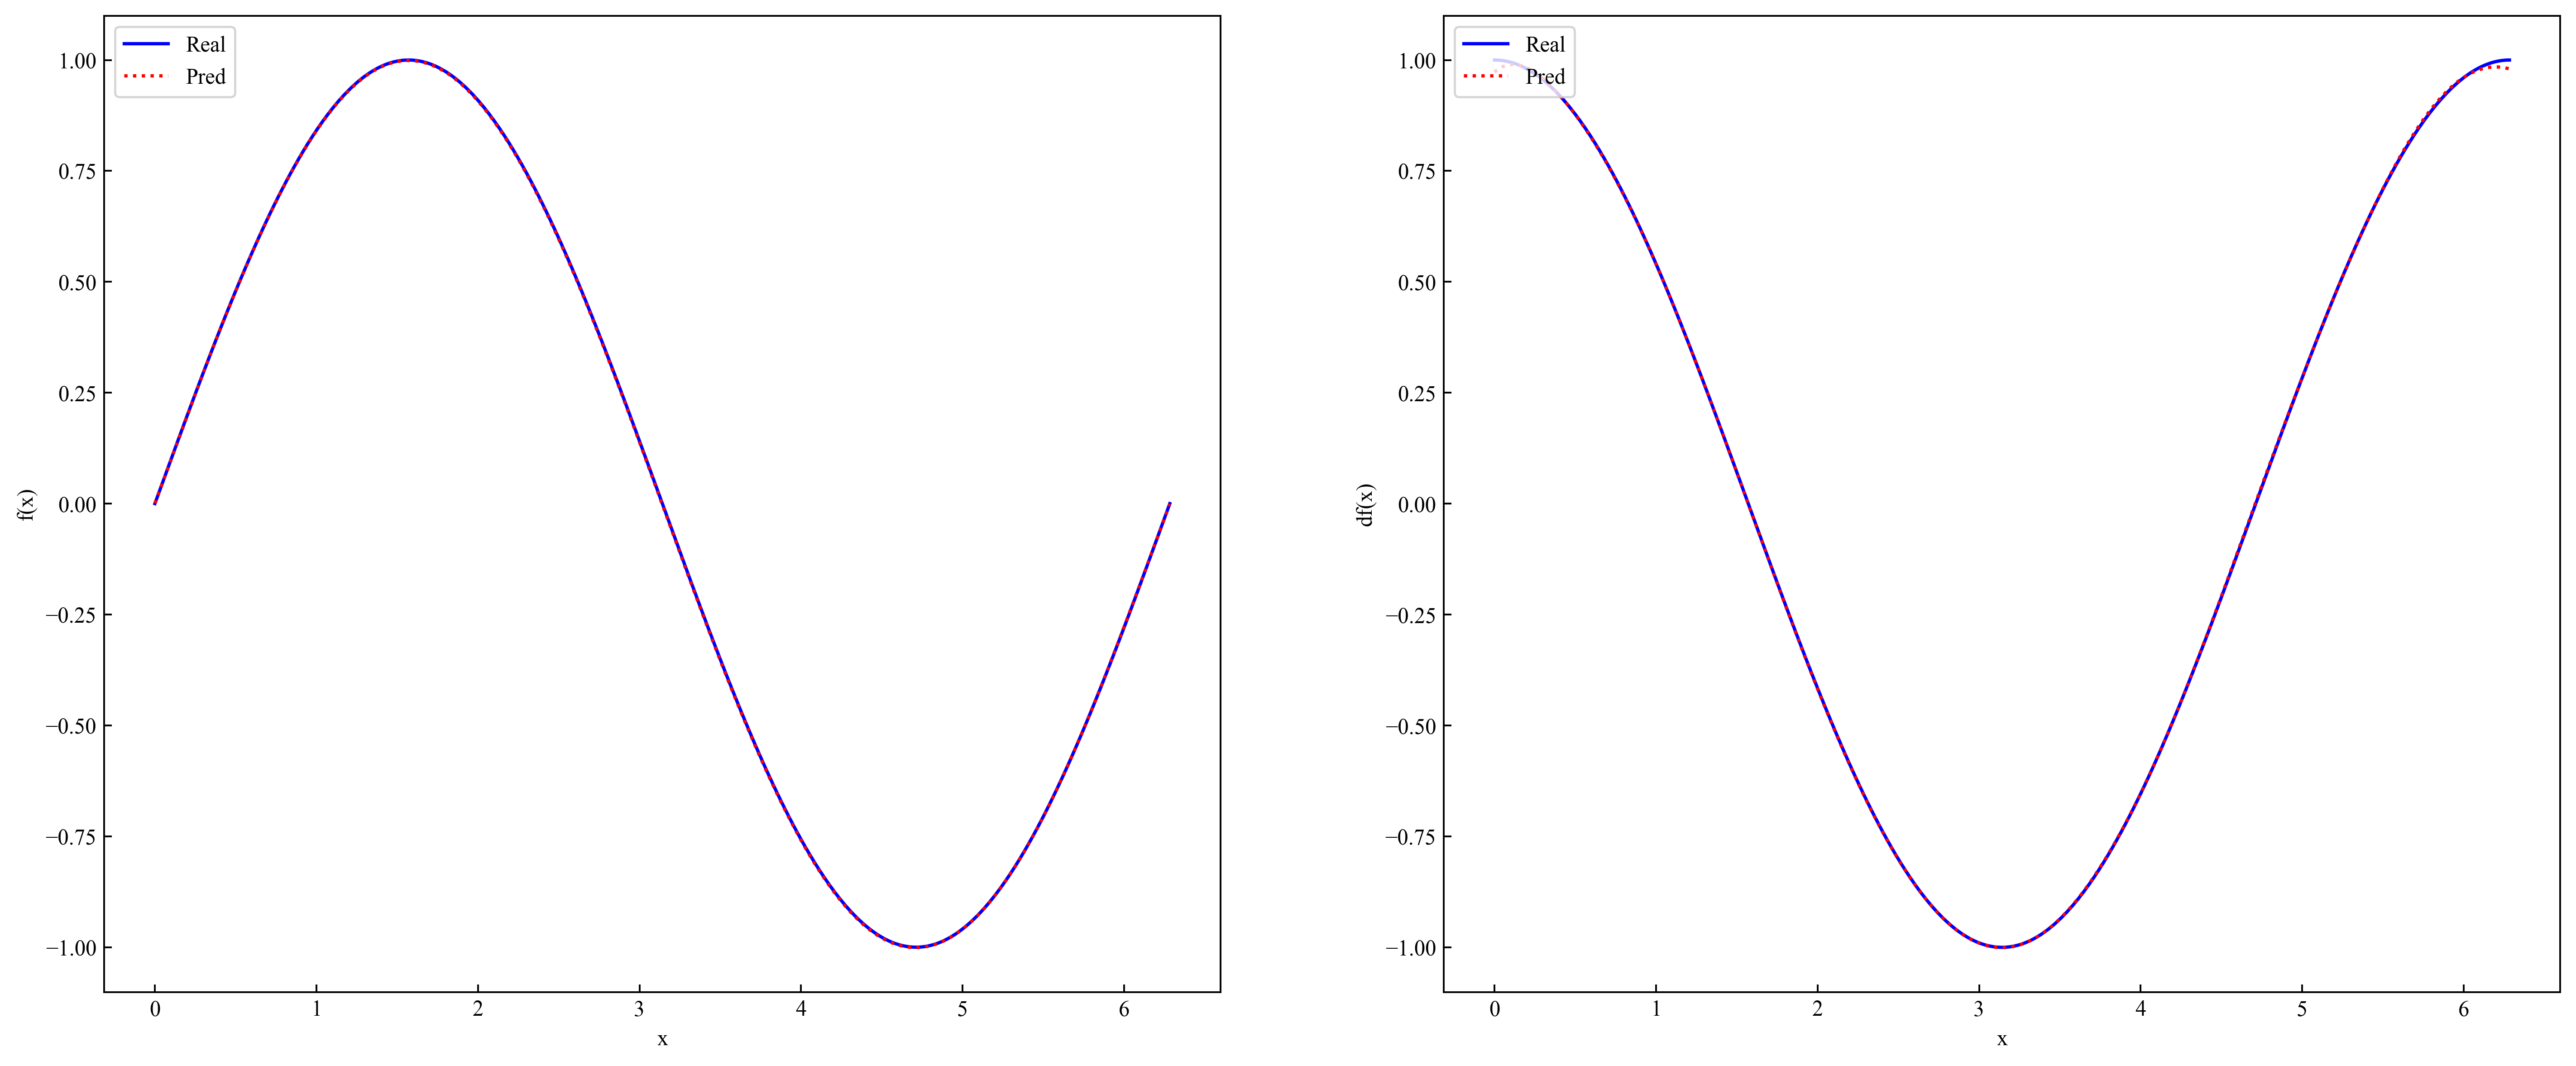

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
ax[0].plot(x_test,y_real,color='blue',label='Real')
ax[0].plot(x_test,y_pred,':',color='red',label='Pred')
ax[0].set_xlabel('x',color='black')
ax[0].set_ylabel('f(x)',color='black')
ax[0].tick_params(axis='y', color='black')
ax[0].legend(loc = 'upper left')

ax[1].plot(x_test,dy_real,color='blue',label='Real')
ax[1].plot(x_test,dy_pred,':',color='red',label='Pred')
ax[1].set_xlabel('x',color='black')
ax[1].set_ylabel('df(x)',color='black')
ax[1].tick_params(axis='y', color='black')
ax[1].legend(loc = 'upper left')

In [11]:
print('MSE for f(x):', np.mean(np.square(y_real-y_pred)))
print('MSE for df(x):', np.mean(np.square(dy_real-dy_pred)))

MSE for f(x): 2.2651595e-06
MSE for df(x): 1.2142566e-05
